# Sprint 3 — Baselines da qualidade do ar em São Paulo

**Trilha B.** Implementação dos três modelos solicitados: `DummyClassifier`, **persistência temporal** e `GaussianNB`.

Os registros, features, limiares CETESB e split seguem a **Sprint 2**. Este notebook usa os arquivos reais da pasta `data/processed/` e o código documentado em `src/sprint3_baselines.py`.

## 1. Encontrar a raiz do projeto e conferir as entradas

Execute o notebook pelo VS Code/Jupyter, com a pasta `Projeto-TrilhaB` aberta.

In [1]:
from pathlib import Path
import sys
import pandas as pd

raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
assert (raiz / "data/processed/treino_features.csv").exists(), "Falta treino_features.csv da Sprint 2"
assert (raiz / "data/processed/teste_features.csv").exists(), "Falta teste_features.csv da Sprint 2"
assert (raiz / "data/interim/integrado_limpo.csv").exists(), "Falta integrado_limpo.csv da Sprint 2"
sys.path.insert(0, str(raiz / "src"))
print("Projeto:", raiz)

Projeto: C:\Users\nogut\Desktop\Projeto Trilha B\Projeto-TrilhaB


## 2. Verificar o corte temporal já definido na Sprint 2

A fronteira de teste continua em **14/04/2026 00:00**. Para evitar que o rótulo de +24 h de um registro de treino dependa de observações do período de teste, o código exclui as 24 horas finais do **treino para modelagem**. O split original não muda.

In [2]:
treino = pd.read_csv(raiz / "data/processed/treino_features.csv", parse_dates=["timestamp"])
teste = pd.read_csv(raiz / "data/processed/teste_features.csv", parse_dates=["timestamp"])
print("N do treino da Sprint 2:", len(treino))
print("N do teste da Sprint 2:", len(teste))
print("Ultima hora treino:", treino["timestamp"].max())
print("Primeira hora teste:", teste["timestamp"].min())
print("Distribuicao do alvo no treino:")
display(treino["qualidade_inadequada_24h"].value_counts().sort_index())

N do treino da Sprint 2: 14016
N do teste da Sprint 2: 3480
Ultima hora treino: 2026-04-13 23:00:00
Primeira hora teste: 2026-04-14 00:00:00
Distribuicao do alvo no treino:


qualidade_inadequada_24h
0    12067
1     1949
Name: count, dtype: int64

## 3. Executar os três baselines

O código contém três Pipelines:

1. `DummyClassifier`: sempre escolhe a classe majoritária no treino; serve como referência de acurácia.
2. `PersistenciaClassifier`: prevê a condição em t+24 h igual à condição observada em t, calculada com histórico até t. É uma regra temporal, não usa classe futura.
3. `GaussianNB`: Naive Bayes probabilístico treinado nas 39 features originais, após imputação mediana e normalização no Pipeline.

`fit` é feito somente no treino; o teste é usado uma vez na avaliação.

In [3]:
import sprint3_baselines
print("Features usadas pelo Dummy e Naive Bayes:", len(sprint3_baselines.FEATURES))
print("Corte:", sprint3_baselines.CUTOFF)
sprint3_baselines.main()

Features usadas pelo Dummy e Naive Bayes: 39
Corte: 2026-04-14 00:00:00

=== SPRINT 3 - TRES BASELINES (RESULTADOS REAIS) ===
Treino CSV: 14016 | treino utilizado: 13992 (purga: 24) | teste: 3480
               modelo  n_teste  acuracia  precisao_classe_1  recall_classe_1  f1_classe_1   tn  fp  fn  tp
      DummyClassifier     3480    0.9141             0.0000           0.0000       0.0000 3181   0 299   0
Persistencia temporal     3480    0.9106             0.4801           0.4849       0.4825 3024 157 154 145
 Gaussian Naive Bayes     3480    0.8626             0.2854           0.3980       0.3324 2883 298 180 119

Arquivos salvos em C:\Users\nogut\Desktop\Projeto Trilha B\Projeto-TrilhaB\reports\sprint3


## 4. Comparar precisão, recall, F1 e falsos negativos

Nosso projeto considera **falso negativo** o erro mais grave (classificar como adequada uma hora em que a condição real é inadequada). Por isso, avalie especialmente **recall da classe 1** e **FN absoluto**.

In [4]:
comparativo = pd.read_csv(raiz / "reports/sprint3/comparativo_baselines.csv")
por_classe = pd.read_csv(raiz / "reports/sprint3/metricas_por_classe.csv")
display(comparativo.round(4))
display(por_classe.round(4))

,modelo,n_teste,acuracia,precisao_classe_1,recall_classe_1,f1_classe_1,tn,fp,fn,tp
0,DummyClassifier,3480,0.9141,0.0000,0.0000,0.0000,3181,0,299,0
1,Persistencia temporal,3480,0.9106,0.4801,0.4849,0.4825,3024,157,154,145
2,Gaussian Naive Bayes,3480,0.8626,0.2854,0.3980,0.3324,2883,298,180,119


,modelo,classe,precisao,recall,f1,suporte
0,DummyClassifier,0,0.9141,1.0000,0.9551,3181
1,DummyClassifier,1,0.0000,0.0000,0.0000,299
2,Persistencia temporal,0,0.9515,0.9506,0.9511,3181
3,Persistencia temporal,1,0.4801,0.4849,0.4825,299
4,Gaussian Naive Bayes,0,0.9412,0.9063,0.9234,3181
5,Gaussian Naive Bayes,1,0.2854,0.3980,0.3324,299


## 5. Matrizes de confusão

Linhas = classe real; colunas = classe prevista. A célula **FN** corresponde a real 1 / previsto 0.

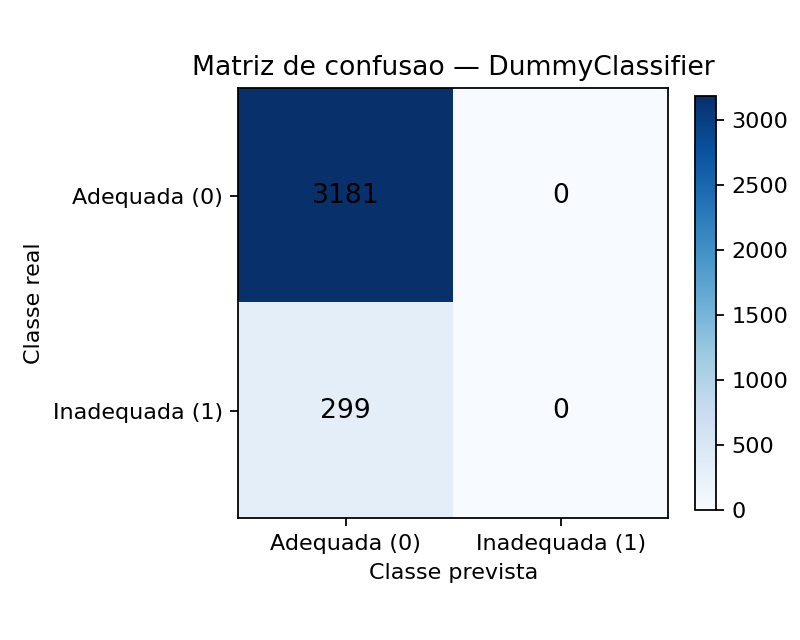

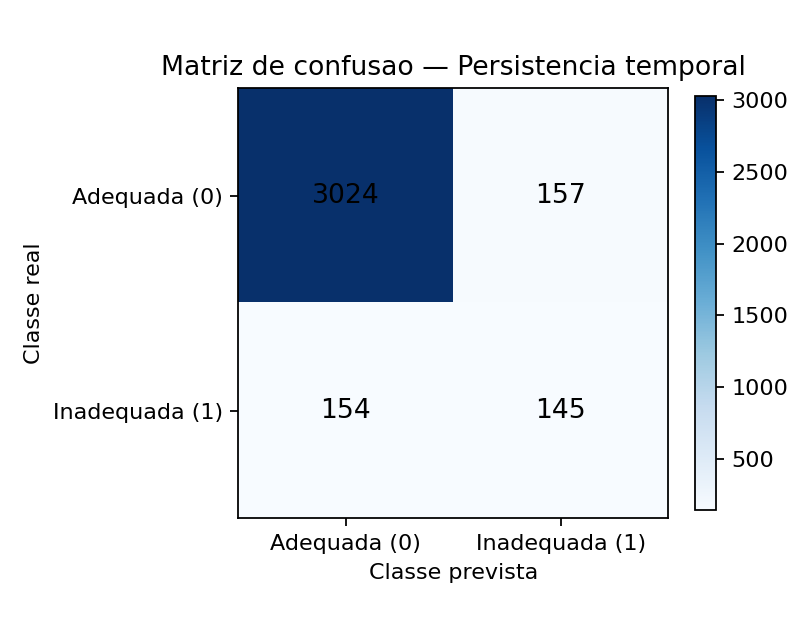

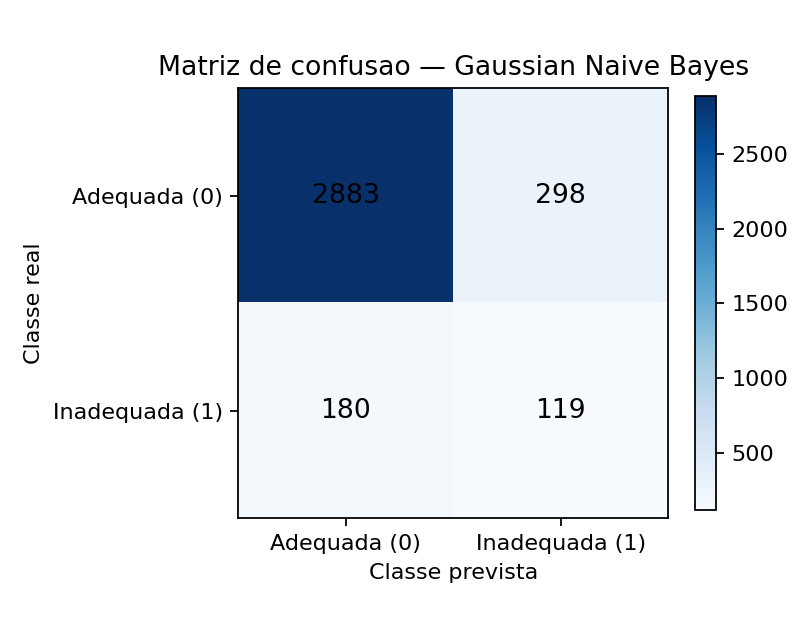

In [5]:
from IPython.display import display, Image
for stem in ("dummy", "persistencia", "naive_bayes"):
    display(Image(filename=str(raiz / f"reports/sprint3/matriz_{stem}.png")))

## 6. Identificar erros que servirão de base para a Sprint 4

Investigue em quais horários os modelos deixam de identificar a condição inadequada, sem usar essa inspeção para alterar os resultados do teste da Sprint 3.

In [6]:
erros = pd.read_csv(raiz / "reports/sprint3/erros_por_horario.csv", parse_dates=["timestamp"])
print("Quantidade de falsos negativos por modelo:")
display(erros.loc[erros.erro.eq("FN")].groupby("modelo").size().rename("FN"))
print("Exemplos de horarios de FN:")
display(erros.loc[erros.erro.eq("FN")].head(12))

Quantidade de falsos negativos por modelo:


modelo
DummyClassifier          299
Gaussian Naive Bayes     180
Persistencia temporal    154
Name: FN, dtype: int64

Exemplos de horarios de FN:


,timestamp,modelo,real,previsto,erro
15,2026-04-14 15:00:00,DummyClassifier,1,0,FN
16,2026-04-14 16:00:00,DummyClassifier,1,0,FN
17,2026-04-14 17:00:00,DummyClassifier,1,0,FN
18,2026-04-14 18:00:00,DummyClassifier,1,0,FN
19,2026-04-14 19:00:00,DummyClassifier,1,0,FN
40,2026-04-15 16:00:00,DummyClassifier,1,0,FN
41,2026-04-15 17:00:00,DummyClassifier,1,0,FN
42,2026-04-15 18:00:00,DummyClassifier,1,0,FN
43,2026-04-15 19:00:00,DummyClassifier,1,0,FN
62,2026-04-16 14:00:00,DummyClassifier,1,0,FN


## 7. Conclusão a registrar no diário

Após a execução com os dados reais, descreva qual modelo teve maior **recall da classe 1**, quantos **FN** ele produziu, se o aumento de recall veio com aumento de **FP**, e como esses erros podem motivar novas features na Sprint 4.

**Não copie métricas de testes com dados sintéticos.** O Naive Bayes é apenas um baseline; a hipótese de independência condicional não representa necessariamente a relação real entre poluentes correlacionados.